In [1]:
import sys, pandas as pd, numpy as np, sklearn
print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| sklearn", sklearn.__version__)

SEED = 42
df = pd.read_csv("../data/PhiUSIIL_Phishing_URL_Dataset.csv")
print(df.shape)
df.head()


Python 3.14.8 | pandas 3.1.1 | sklearn 1.9.1
(235795, 56)


,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,...,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,...,1,0,1,244,15,34,72,1,85,1


In [2]:
df.info()
print("Missing values:", df.isna().sum().sum())
print("Duplicated URLs:", df["URL"].duplicated().sum())
dups = df[df["URL"].duplicated(keep=False)]
print("Duplicates with different labels:", (dups.groupby("URL")["label"].nunique() > 1).sum())

<class 'pandas.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 56 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   FILENAME                    235795 non-null  str    
 1   URL                         235795 non-null  str    
 2   URLLength                   235795 non-null  int64  
 3   Domain                      235795 non-null  str    
 4   DomainLength                235795 non-null  int64  
 5   IsDomainIP                  235795 non-null  int64  
 6   TLD                         235795 non-null  str    
 7   URLSimilarityIndex          235795 non-null  float64
 8   CharContinuationRate        235795 non-null  float64
 9   TLDLegitimateProb           235795 non-null  float64
 10  URLCharProb                 235795 non-null  float64
 11  TLDLength                   235795 non-null  int64  
 12  NoOfSubDomain               235795 non-null  int64  
 13  HasObfuscation           

No missing values. 425 duplicated URLs, none with conflicting labels: we remove them before splitting to avoid leakage.

(235370, 57)
is_phishing
0    134850
1    100520
Name: count, dtype: int64
Share of phishing: 0.427


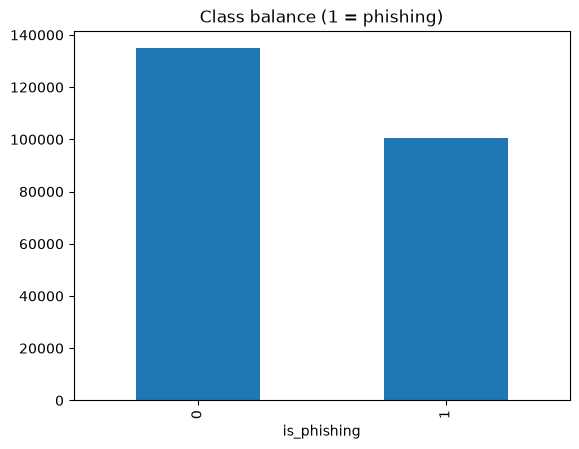

is_phishing    0         1
URL                       
False        0.0  0.989694
True         1.0  0.010306
Accuracy of a one-line rule: 0.9956


In [3]:
import matplotlib.pyplot as plt
df = df.drop_duplicates(subset="URL").reset_index(drop=True)
df["is_phishing"] = 1 - df["label"]
print(df.shape)
print(df["is_phishing"].value_counts())
print("Share of phishing:", round(df["is_phishing"].mean(), 3))
df["is_phishing"].value_counts().plot(kind="bar", title="Class balance (1 = phishing)")
plt.show()
pattern = df["URL"].str.match(r"^https://www\.[^/]+/?$")
print(pd.crosstab(pattern, df["is_phishing"], normalize="columns"))
print("Accuracy of a one-line rule:", round(((~pattern).astype(int) == df["is_phishing"]).mean(), 4))

Class balance and sampling bias
- After removing 425 duplicated URLs, 235,370 URLs remain, 42.7% phishing. The imbalance is mild (57/43), so no resampling; we still report PR-AUC, precision and recall rather than accuracy.
- 100% of legitimate URLs have the form `https://www.<host>` with no path, against about 1% of phishing URLs. A one-line rule on this pattern reaches 99.56% accuracy.
- This is a sampling artifact, not evidence of phishing. We therefore compare Set A (full URL) with Set B (host only) and test on an external dataset (URL-Phish).

,mean,50%,max
URLLength,34.55,27.00,6097.00
DomainLength,21.46,20.00,110.00
IsDomainIP,0.00,0.00,1.00
TLDLength,2.76,3.00,13.00
NoOfSubDomain,1.16,1.00,10.00
HasObfuscation,0.00,0.00,1.00
NoOfObfuscatedChar,0.02,0.00,447.00
ObfuscationRatio,0.00,0.00,0.35
NoOfLettersInURL,19.41,14.00,5191.00
LetterRatioInURL,0.52,0.52,0.93


Limit: 50.5 | outliers: 22362 | share phishing among them: 0.999


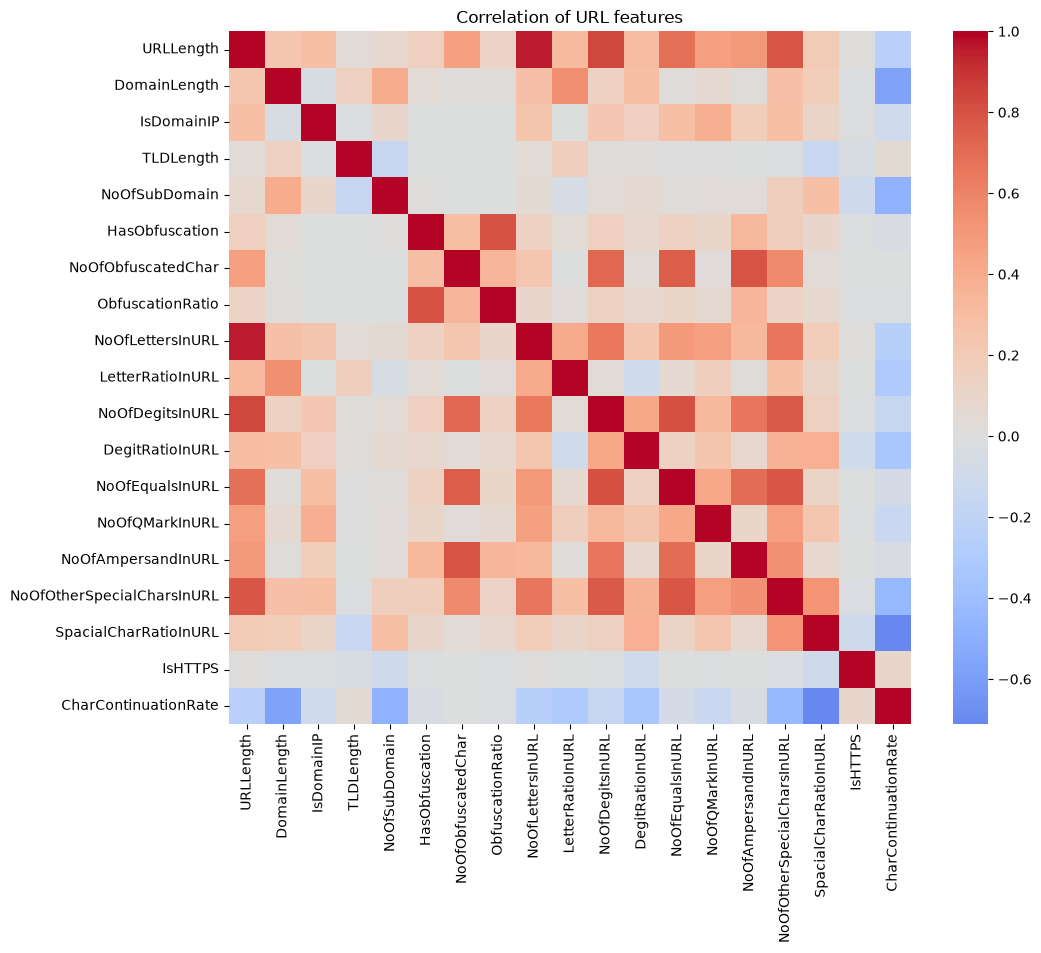

URLLength  NoOfLettersInURL    0.956046
dtype: float64


In [4]:
import seaborn as sns
url_cols = ["URLLength","DomainLength","IsDomainIP","TLDLength","NoOfSubDomain","HasObfuscation",
            "NoOfObfuscatedChar","ObfuscationRatio","NoOfLettersInURL","LetterRatioInURL",
            "NoOfDegitsInURL","DegitRatioInURL","NoOfEqualsInURL","NoOfQMarkInURL",
            "NoOfAmpersandInURL","NoOfOtherSpecialCharsInURL","SpacialCharRatioInURL",
            "IsHTTPS","CharContinuationRate"]
display(df[url_cols].describe().T[["mean","50%","max"]].round(2))

q1, q3 = df["URLLength"].quantile([0.25, 0.75])
limit = q3 + 1.5 * (q3 - q1)
outliers = df["URLLength"] > limit
print("Limit:", limit, "| outliers:", outliers.sum(), "| share phishing among them:", round(df.loc[outliers, "is_phishing"].mean(), 3))

corr = df[url_cols].corr()
plt.figure(figsize=(11, 9)); sns.heatmap(corr, cmap="coolwarm", center=0); plt.title("Correlation of URL features"); plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
print(pairs[pairs.abs() > 0.9])

Outliers and correlations
- We keep only features computed from the URL string. Page-content columns and URLSimilarityIndex, TLDLegitimateProb and URLCharProb (built from dataset-wide statistics) are excluded to avoid leakage.
- URL length is heavily skewed (median 27, max 6,097). About 22,000 URLs exceed the IQR limit of 50.5 characters, and 99.9% of them are phishing: these outliers are real signal, so we keep them and use a log or robust scaling for linear models.
- Only one pair of features is strongly correlated (URLLength and NoOfLettersInURL, r = 0.96); one of them will be dropped for linear models. Tree models are not affected.

Preprocessing decisions

1. Data cleaning
- No imputation needed:the dataset has no missing values.
- Remove the 425 duplicated URLs before splitting:a URL present in both train and test would let the model "remember" the answer (leakage).
- Recode the target so that phishing = 1: phishing is the class we want to detect, so precision and recall are computed on it.

2. Feature selection
- Keep only features computed from the URL string:** the model must decide before the page is loaded.
- Exclude URLSimilarityIndex, TLDLegitimateProb and URLCharProb:** they are built from statistics of the whole dataset, which leaks test information.
- prop NoOfLettersInURL for linear models: it is almost identical to URLLength (r = 0.96).

**3. Handling the data's particularities
- Keep long URLs (outliers): 99.9% of them are phishing, so they carry real signal; we use log or robust scaling for linear models.
- No resampling: the imbalance is mild (57% / 43%); we use stratified splits and PR-AUC, precision and recall instead of accuracy.
- Control the sampling bias: a one-line rule on `https://www.` reaches 99.56%, so we compare Set A (full URL) with Set B (host only) and test on URL-Phish.

4. Protection against leakage
- Fit the scaler inside a Pipeline, on training folds only.
- Split by site:80/20 train/test, then 5 folds on train, with no site shared between sets.

In [5]:
import tldextract
from urllib.parse import urlsplit
from sklearn.model_selection import StratifiedGroupKFold

ext = tldextract.TLDExtract(suffix_list_urls=(), include_psl_private_domains=True)
def site_of(url):
    site = ext(url).top_domain_under_public_suffix
    return site if site else urlsplit(url).hostname   
df["site"] = df["URL"].map(site_of)
print("Number of sites:", df["site"].nunique())
print(df["site"].value_counts().head(5))

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(sgkf.split(df, df["is_phishing"], groups=df["site"]))
df["split"] = "train"
df.loc[test_idx, "split"] = "test"
print(df["split"].value_counts(normalize=True).round(3))
print(df.groupby("split")["is_phishing"].mean().round(3))

train = df[df["split"] == "train"]
df["fold"] = -1                      
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
for k, (_, val_idx) in enumerate(cv.split(train, train["is_phishing"], groups=train["site"])):
    df.loc[train.index[val_idx], "fold"] = k
print(df[df["split"] == "train"].groupby("fold")["is_phishing"].agg(["size", "mean"]).round(3))

Number of sites: 197709
site
weeblysite.com      3079
ipfs.io             1552
xsph.ru              928
google.com           782
godaddysites.com     770
Name: count, dtype: int64
split
train    0.8
test     0.2
Name: proportion, dtype: float64
split
test     0.427
train    0.427
Name: is_phishing, dtype: float64
       size   mean
fold              
0     37660  0.427
1     37660  0.427
2     37659  0.427
3     37658  0.427
4     37659  0.427


Train/test split grouped by site
- Each URL is mapped to its site (registered domain, using the public suffix list including private suffixes such as web.app; IP addresses keep their host).
- Some sites contain thousands of URLs (weeblysite.com: 3,079), so a random split would let the model recognise sites seen in training and overestimate performance.
- We hold out 20% as a final test set with StratifiedGroupKFold (seed 42): no site appears in both train and test, and both keep 42.7% phishing.
- The training set is divided into 5 grouped, stratified folds for model selection. The test set (fold = -1) is used only once, at the end.

In [6]:
import os

train_sites = set(df.loc[df["split"] == "train", "site"])
test_sites = set(df.loc[df["split"] == "test", "site"])
assert len(train_sites & test_sites) == 0, "A site is in both train and test!"
assert df["URL"].duplicated().sum() == 0, "Duplicated URLs remain!"
for k in range(5):
    tr = set(df.loc[(df["split"] == "train") & (df["fold"] != k), "site"])
    va = set(df.loc[df["fold"] == k, "site"])
    assert len(tr & va) == 0, f"Fold {k} shares sites with the other folds!"
print("All leakage checks passed")

os.makedirs("../splits", exist_ok=True)
df[["URL", "site", "is_phishing", "split", "fold"]].to_csv("../splits/phiusiil_splits.csv.gz", index=False)
print("Saved:", len(df), "rows")

All leakage checks passed
Saved: 235370 rows


Leakage checks and shared split
Automatic checks confirm that no site is shared between train and test or between folds, and that no duplicated URL remains. The split (URL, site, label, split, fold) is saved to `splits/phiusiil_splits.csv.gz` so every team member trains and evaluates on exactly the same sets.